In [9]:
import numpy as np
import torch 
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons

# Dataset and forward

torch.Size([1000, 2])


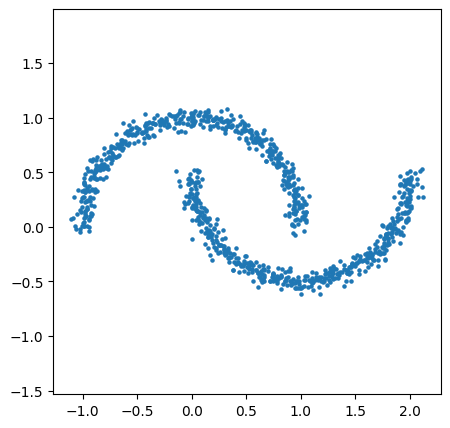

In [3]:
x, _ = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=42
)

x0 = torch.tensor(x, dtype=torch.float32)
print(x0.shape)

plt.figure(figsize=(5, 5))
plt.scatter(x0[:, 0], x0[:, 1], s=5)
plt.axis("equal")
plt.show()

In [4]:
T = 1000 #total step

def schedule(T, low=1e-4, high=0.02, device="cpu"):

    betas = torch.linspace(low, high, T, device=device)

    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)

    sche = {
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,
        "sqrt_alpha_bars": torch.sqrt(alpha_bars),
        "sqrt_one_minus_alpha_bars": torch.sqrt(1.0 - alpha_bars),
    }
    return sche

sched = schedule(T)

print(sched["betas"].shape)
print(sched["alphas"][:5])
print(sched["alpha_bars"][:5])
print(sched["alpha_bars"][-1])

torch.Size([1000])
tensor([0.9999, 0.9999, 0.9999, 0.9998, 0.9998])
tensor([0.9999, 0.9998, 0.9996, 0.9995, 0.9993])
tensor(4.0358e-05)


In [5]:
def q_sample(x0, t, noise, sched, device="cpu"):
    """
    x0: clean data, shape [B, 2]
    t: timestep, [B]
    noise: Gaussian noise, shape [B, 2]
    """
    sqrt_alpha_bar_t = sched["sqrt_alpha_bars"][t].unsqueeze(1)
    sqrt_one_minus_alpha_bar_t = sched["sqrt_one_minus_alpha_bars"][t].unsqueeze(1)

    xt = sqrt_alpha_bar_t * x0 + sqrt_one_minus_alpha_bar_t * noise

    return xt

def sample(x0, T, batch, sched, device="cpu"):
    x0_batch = x0[torch.randint(0, x0.shape[0], (batch,))].to(device)
    t = torch.randint(0, T, (batch,), device=device)
    noise = torch.randn_like(x0_batch, device=device)

    xt = q_sample(x0 = x0_batch, t = t, noise = noise, sched=sched, device=device)
    return xt, t, noise

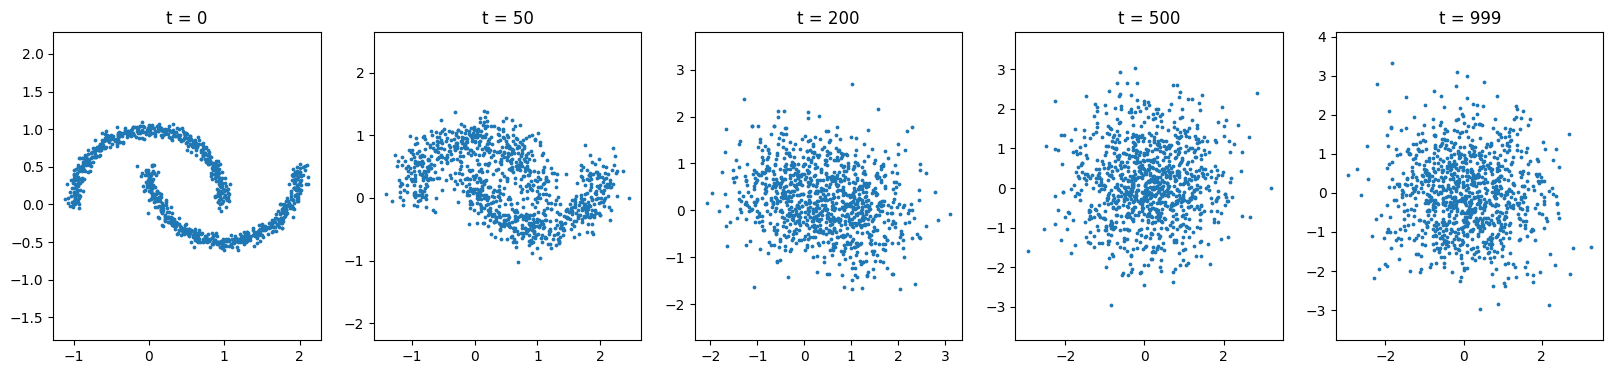

In [6]:
time_step = [0, 50, 200, 500, 999]

fig, axes = plt.subplots(1, 5, figsize=(20,4))

for ax, t in zip(axes, time_step):
    noise = torch.randn_like(x0)
    t_all = torch.full((x0.shape[0],), t, dtype=torch.long)
    xt = q_sample(x0, t_all, noise, sched)

    ax.scatter(
        xt[:,0],
        xt[:,1],
        s=3
    )
    ax.set_title(f"t = {t}")
    ax.axis("equal")
plt.show()

In [7]:
class noisePredictor(nn.Module):
    def __init__(self,T):
        super().__init__()
        self.T = T
        self.fc1 = torch.nn.Linear(3,128)   # single sample dim (x1, x2, t)
        self.fc2 = nn.Linear(128,64)
        self.fc3 = nn.Linear(64,2)
    def forward(self,xt,t):
        t = t.to(xt.device)
        t = t.float()/self.T
        t = t.unsqueeze(1)
        x_input = torch.cat([xt, t], dim=1)
        x = F.relu(self.fc1(x_input))
        x = F.relu(self.fc2(x))
        x_output = self.fc3(x)
        return x_output

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = noisePredictor(T).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
x0 = x0.to(device)


def train(model, epochs, T, B, device):
    history = []
    sched = schedule(T, device=device)
    for epoch in range(epochs):
        xt, t, noise = sample(x0, T, B, sched, device=device)

        noise_pred = model(xt, t)

        loss = F.mse_loss(noise_pred, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history.append(loss.item())
        if (epoch+1)%1000 == 0:
            avg_loss = sum(history[-100:])/len(history[-100:])
            print(f'epoch = {epoch+1}, loss = {loss.item():.4f}, avg_loss = {avg_loss:.4f}')
    return history

epochs = 20000
B = 512
T = 1000
train(model, epochs, T, B, device)
print("model device =", next(model.parameters()).device)       

epoch = 1000, loss = 0.2031, avg_loss = 0.1971
epoch = 2000, loss = 0.1752, avg_loss = 0.1894
epoch = 3000, loss = 0.2078, avg_loss = 0.1857
epoch = 4000, loss = 0.1482, avg_loss = 0.1871
epoch = 5000, loss = 0.1463, avg_loss = 0.1802
epoch = 6000, loss = 0.1867, avg_loss = 0.1845
epoch = 7000, loss = 0.2180, avg_loss = 0.1854
epoch = 8000, loss = 0.1971, avg_loss = 0.1842
epoch = 9000, loss = 0.1826, avg_loss = 0.1799
epoch = 10000, loss = 0.1579, avg_loss = 0.1791
epoch = 11000, loss = 0.1618, avg_loss = 0.1807
epoch = 12000, loss = 0.1615, avg_loss = 0.1802
epoch = 13000, loss = 0.1837, avg_loss = 0.1797
epoch = 14000, loss = 0.1570, avg_loss = 0.1783
epoch = 15000, loss = 0.2057, avg_loss = 0.1790
epoch = 16000, loss = 0.1763, avg_loss = 0.1799
epoch = 17000, loss = 0.1543, avg_loss = 0.1764
epoch = 18000, loss = 0.1734, avg_loss = 0.1780
epoch = 19000, loss = 0.1890, avg_loss = 0.1776
epoch = 20000, loss = 0.2436, avg_loss = 0.1790
model device = cuda:0


# DDIM inference

DDIM inference can be understood as moving backward along the same forward noising trajectory. The forward process has a closed-form expression:

$$x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$$

Given the current noisy sample $x_t$ and the noise predicted by the model, $\epsilon_\theta(x_t,t)$, we can estimate the clean sample that would have produced this $x_t$:

$$\hat{x}_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}$$

This is what the following lines do in the code:

```python
noise = model(x, t_batch)
x0 = (x - noise * sched["sqrt_one_minus_alpha_bars"][t]) / sched["sqrt_alpha_bars"][t]
```

Then, instead of sampling a new random noise term at every reverse step as in DDPM, DDIM reuses the predicted noise and directly constructs the sample at an earlier timestep $s$:

$$x_s = \sqrt{\bar\alpha_s}\hat{x}_0 + \sqrt{1-\bar\alpha_s}\epsilon_\theta(x_t,t)$$

In the code, this corresponds to:

```python
x = sched["sqrt_alpha_bars"][s] * x0 + sched["sqrt_one_minus_alpha_bars"][s] * noise
```

This is why DDIM can remain deterministic or static. With eta = 0, no extra Gaussian randomness is injected during the reverse steps. If the initial $x_T$, the model, and the timestep schedule are the same, the entire sampling path is fixed, so the output is fixed as well. The only randomness comes from the initial `torch.randn(N, 2)`.

Why are $x_t$ and $\hat{x}_0$ enough? Because every timestep in the forward distribution can be written as a linear combination of clean data and noise. Once the model predicts the noise from $x_t$, the pair $\hat{x}_0$ and that noise describes the trajectory of the current sample. To obtain any earlier sample $x_s$, we only need to change the coefficients to $\sqrt{\bar\alpha_s}$ and $\sqrt{1-\bar\alpha_s}$ and combine them again. We do not need to explicitly visit every intermediate timestep.

This also explains why DDIM can skip steps. DDPM usually models the stochastic transition between adjacent timesteps, $p(x_{t-1}\mid x_t)$, so it naturally takes many small reverse steps. DDIM uses a non-Markovian deterministic update that can map directly from timestep $t$ to any smaller timestep $s$. As long as the schedule provides $\bar\alpha_s$, we can compute $x_s$. This is why the notebook can use `torch.linspace(T-1, 0, steps)` to choose fewer sampling steps, such as 1000, 200, 100, 50, or 20. Fewer steps make sampling faster, but prediction errors from the model can become larger, so sample quality may become less stable.

In [11]:
@torch.no_grad()
def ddim_inference(model, N, T, steps, device):
    model.eval()

    x = torch.randn(N, 2, device=device)

    timesteps = torch.linspace(T-1, 0, steps, device=device).round().long()

    sched = schedule(T, device=device)

    for i in range(len(timesteps)):
        t = timesteps[i]
        t_batch = torch.full((N,), t.item(), device=device, dtype=torch.long)

        noise = model(x,t_batch)
        x0 = (x - noise*sched["sqrt_one_minus_alpha_bars"][t]) / sched["sqrt_alpha_bars"][t]

        if i < (len(timesteps)-1):
            s = timesteps[i+1]
            x = sched["sqrt_alpha_bars"][s] * x0 + sched["sqrt_one_minus_alpha_bars"][s] * noise
        else:
            return x0


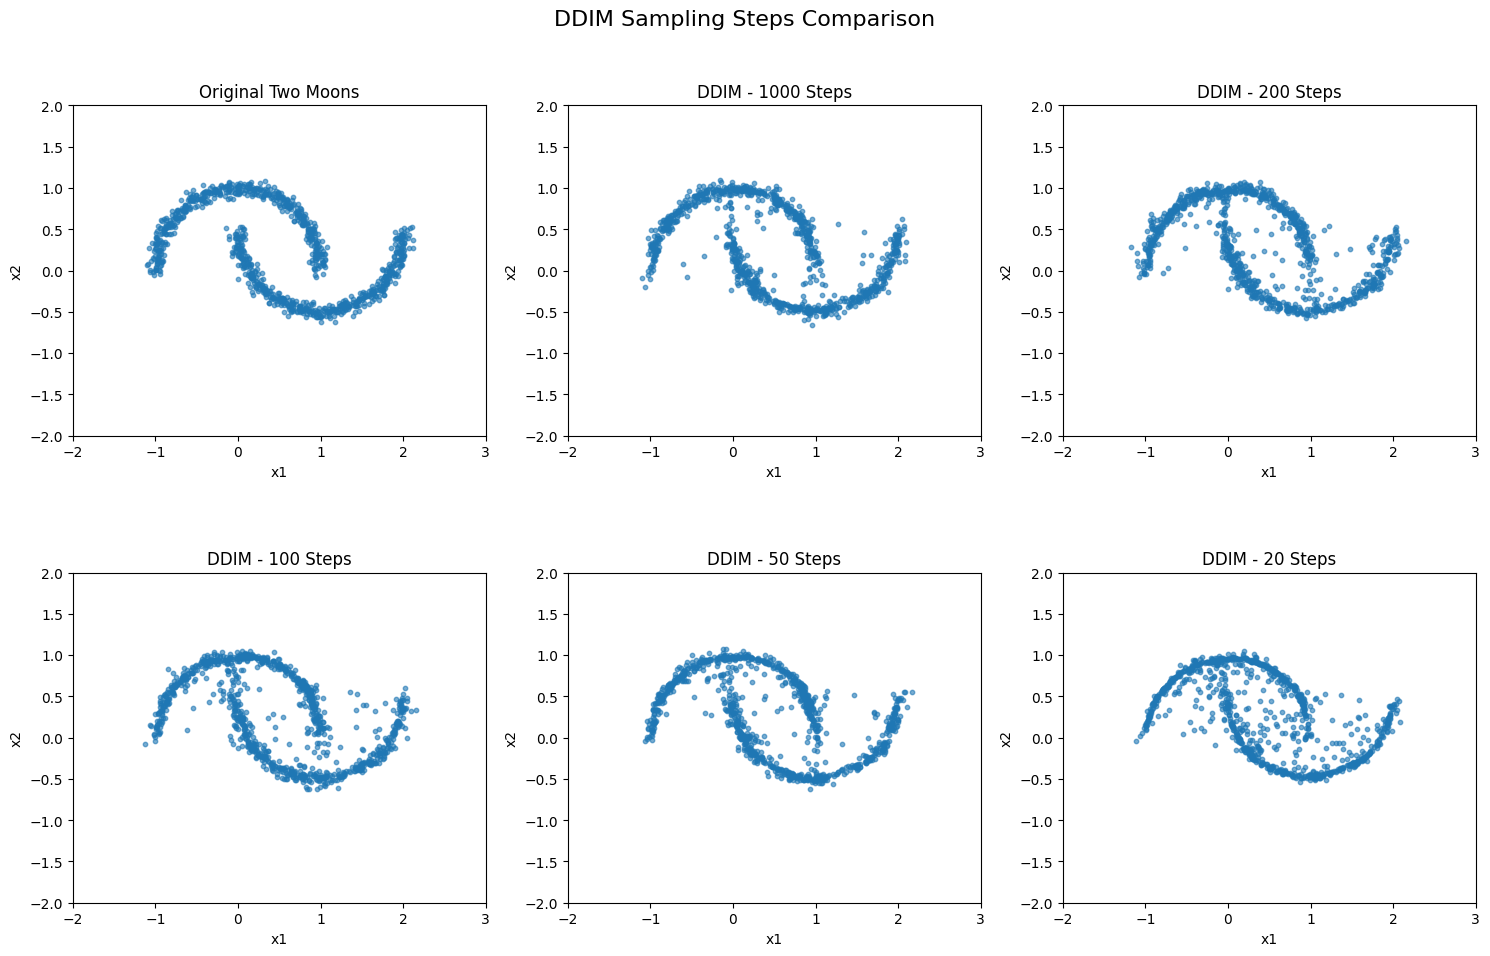

In [15]:
N = 1000
T = 1000
steps_list = [1000, 200, 100, 50, 20]

fig, axes = plt.subplots(2,3,figsize=(15,10))
axes = axes.flatten()

axes[0].scatter(
    x0[:, 0].cpu().numpy(),
    x0[:, 1].cpu().numpy(),
    s=10,
    alpha=0.6
)
axes[0].set_title("Original Two Moons")

for i,steps in enumerate(steps_list, start=1):
    samples = ddim_inference(model, N, T, steps, device)
    samples = samples.cpu().numpy()

    axes[i].scatter(samples[:,0], samples[:,1], s=10, alpha=0.6)
    axes[i].set_title(f"DDIM - {steps} Steps")

for ax in axes:
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-2, 3)
    ax.set_ylim(-2, 2)

plt.suptitle("DDIM Sampling Steps Comparison", fontsize=16)
plt.tight_layout()
plt.show()